# Evaluacion de Fitness con Gaussian Naive Bayes y Spark RDD

**Objetivo:** Sustituir la funcion fitness dummy del prototipo anterior por una evaluacion real basada en un clasificador Gaussian Naive Bayes (GNB) de scikit-learn, manteniendo la evaluacion paralela con Spark.

**Que se implementa:**
1. Carga del dataset Wisconsin Breast Cancer (WDBC) — 30 caracteristicas, 569 muestras
2. Funcion fitness real: entrena GNB con el subconjunto de caracteristicas activas del cromosoma y calcula accuracy mediante validacion cruzada de 5 pliegues
3. Formula: $\text{Fitness}(\mathbf{c}) = \alpha \cdot \text{Accuracy}_{CV5}(\mathbf{c}) - \beta \cdot \frac{|S|}{D}$
4. Evaluacion paralela con Spark RDD y comparacion con ejecucion secuencial
5. Ciclo evolutivo completo de varias generaciones

---
## 1. Setup: Spark Session e Imports

In [16]:
import sys
sys.path.insert(0, '../src')

from spark_config import crear_sesion_spark, mostrar_info_spark, parar_spark
import numpy as np
import time
from datetime import datetime
from sklearn.datasets import load_breast_cancer
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import cross_val_score

print(f"Notebook iniciado: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Notebook iniciado: 2026-04-17 13:13:13


In [17]:
spark = crear_sesion_spark(
    app_name="TFM_GNB_Fitness",
    master="local[*]",
    driver_memory="4g",
    executor_memory="4g",
    ui_port=4040,
    verbose=False
)

sc = spark.sparkContext
mostrar_info_spark(spark, ui_port=4040)

NUM_CORES = sc.defaultParallelism
print(f"\nCores disponibles para paralelismo: {NUM_CORES}")

🔥 INFORMACIÓN DE SPARK SESSION
✓ App Name: TFM_GNB_Fitness
✓ Master: local[*]
✓ Spark Version: 3.5.0
✓ Python Version: 3.9
✓ Default Parallelism: 4
✓ Default Min Partitions: 2

🌐 SPARK WEB UI
📊 Accede en tu navegador a:
   👉 http://localhost:4040

   Opciones disponibles:
   - Jobs: Ver trabajos en ejecución/completados
   - Stages: Ver stages de cada job
   - Storage: Ver RDDs cacheados
   - Environment: Configuración de Spark
   - Executors: Estado de ejecutores


Cores disponibles para paralelismo: 4


---
## 2. Carga del Dataset WDBC (Wisconsin Diagnostic Breast Cancer)

El dataset tiene 30 caracteristicas numericas y una variable objetivo binaria (maligno/benigno). Las 30 caracteristicas corresponden exactamente a la longitud del cromosoma $D = 30$.

In [18]:
# Cargar dataset
dataset = load_breast_cancer()
X = dataset.data    # (569, 30)
y = dataset.target  # 0=maligno, 1=benigno
D = X.shape[1]      # 30 caracteristicas
feature_names = dataset.feature_names

print(f"Dataset: {dataset.DESCR.splitlines()[0]}")
print(f"Muestras: {X.shape[0]}")
print(f"Caracteristicas (D): {D}")
print(f"Clases: {dict(zip(dataset.target_names, np.bincount(y)))}")
print(f"\nPrimeras 5 caracteristicas: {list(feature_names[:5])}")

Dataset: .. _breast_cancer_dataset:
Muestras: 569
Caracteristicas (D): 30
Clases: {'malignant': 212, 'benign': 357}

Primeras 5 caracteristicas: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']


---
## 3. Generacion de la Poblacion

Cada individuo es un cromosoma binario de longitud $D = 30$, representando un subconjunto candidato de caracteristicas. Se genera una poblacion de $P$ individuos con inicializacion aleatoria ($p_{init} = 0.5$).

In [19]:
# Parametros de la poblacion
P = 100          # Tamano de la poblacion
P_INIT = 0.5     # Probabilidad de inicializacion de cada gen

np.random.seed(42)
poblacion = [list(np.random.binomial(1, P_INIT, D)) for _ in range(P)]

print(f"Poblacion generada: {P} individuos, cromosoma de longitud {D}")
print(f"Ejemplo individuo[0]: {poblacion[0]}")
print(f"Genes activos en individuo[0]: {sum(poblacion[0])}/{D}")

Poblacion generada: 100 individuos, cromosoma de longitud 30
Ejemplo individuo[0]: [0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0]
Genes activos en individuo[0]: 13/30


---
## 4. Funcion Fitness con Gaussian Naive Bayes

La funcion fitness entrena un clasificador **Gaussian Naive Bayes** usando unicamente las caracteristicas activas (genes = 1) del cromosoma, y evalua su rendimiento con **validacion cruzada de 5 pliegues**.

$$\text{Fitness}(\mathbf{c}) = \alpha \cdot \text{Accuracy}_{CV5}(\mathbf{c}) - \beta \cdot \frac{|S|}{D}$$

Donde:
- $|S|$ = numero de caracteristicas seleccionadas (genes activos)
- $D$ = total de caracteristicas (30)
- $\alpha = 0.9$ pondera la precision del clasificador
- $\beta = 0.1$ penaliza el numero de caracteristicas (favorece subconjuntos mas pequenos)

> **Nota:** Para la evaluacion paralela con Spark, los datos `X` e `y` se envian como variables broadcast para evitar copias redundantes a los workers.

In [20]:
ALPHA = 0.9
BETA = 0.1
CV_FOLDS = 5

# Broadcast de los datos para Spark (evita copias redundantes a workers)
X_bc = sc.broadcast(X)
y_bc = sc.broadcast(y)


def evaluar_fitness(cromosoma):
    """Evalua el fitness de un cromosoma usando GNB con validacion cruzada.

    1. Selecciona las columnas de X correspondientes a genes activos (=1)
    2. Entrena GaussianNB con 5-fold cross-validation
    3. Calcula: fitness = alpha * accuracy_media - beta * (n_activos / D)

    Si el cromosoma no tiene genes activos, retorna 0.0.
    """
    indices_activos = [i for i, gen in enumerate(cromosoma) if gen == 1]
    d = len(cromosoma)

    if len(indices_activos) == 0:
        return 0.0

    X_data = X_bc.value[:, indices_activos]
    y_data = y_bc.value

    gnb = GaussianNB()
    scores = cross_val_score(gnb, X_data, y_data, cv=CV_FOLDS, scoring='accuracy')
    accuracy = scores.mean()

    penalizacion = len(indices_activos) / d
    return round(ALPHA * accuracy - BETA * penalizacion, 6)


# Test rapido con un individuo
test_cromosoma = poblacion[0]
test_fitness = evaluar_fitness(test_cromosoma)
genes_activos = sum(test_cromosoma)

print(f"Test fitness individuo[0]:")
print(f"  Genes activos: {genes_activos}/{D}")
print(f"  Caracteristicas seleccionadas: {list(feature_names[np.array(test_cromosoma) == 1])}")
print(f"  Fitness: {test_fitness:.6f}")

# Verificar con todas las caracteristicas
cromosoma_completo = [1] * D
fitness_completo = evaluar_fitness(cromosoma_completo)
print(f"\nBaseline (todas las caracteristicas):")
print(f"  Fitness: {fitness_completo:.6f}")

Test fitness individuo[0]:
  Genes activos: 13/30
  Caracteristicas seleccionadas: ['mean texture', 'mean perimeter', 'mean area', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'texture error', 'perimeter error', 'concave points error', 'worst radius', 'worst compactness', 'worst concave points', 'worst symmetry']
  Fitness: 0.798134

Baseline (todas las caracteristicas):
  Fitness: 0.744667


---
## 5. Evaluacion Secuencial (Baseline)

Evaluamos toda la poblacion con Python puro (un solo hilo) para tener un baseline de tiempo.

In [21]:
print(f"=" * 60)
print(f"EVALUACION SECUENCIAL (Python puro)")
print(f"Poblacion: {P} individuos | Clasificador: GNB | CV: {CV_FOLDS}-fold")
print(f"=" * 60)

inicio_seq = time.time()
fitness_seq = [evaluar_fitness(ind) for ind in poblacion]
tiempo_seq = time.time() - inicio_seq

print(f"\nTiempo secuencial: {tiempo_seq:.2f}s")
print(f"Mejor fitness: {max(fitness_seq):.6f}")
print(f"Fitness medio: {np.mean(fitness_seq):.6f}")
print(f"Peor fitness:  {min(fitness_seq):.6f}")
print(f"Tiempo por individuo: {tiempo_seq/P*1000:.1f}ms")

EVALUACION SECUENCIAL (Python puro)
Poblacion: 100 individuos | Clasificador: GNB | CV: 5-fold

Tiempo secuencial: 0.25s
Mejor fitness: 0.825895
Fitness medio: 0.787899
Peor fitness:  0.763586
Tiempo por individuo: 2.5ms


---
## 6. Evaluacion Paralela con Spark RDD

La poblacion se distribuye como un RDD y cada individuo se evalua en paralelo con `rdd.map()`. Los datos del dataset se comparten via broadcast.

```python
fitness_scores = RDD(poblacion).map(evaluar_fitness).collect()
```

In [22]:
print(f"=" * 60)
print(f"EVALUACION PARALELA (Spark RDD)")
print(f"Poblacion: {P} individuos | Particiones: {NUM_CORES}")
print(f"Clasificador: GNB | CV: {CV_FOLDS}-fold")
print(f"=" * 60)
print(f"\n>>> Abre http://localhost:4040 para observar la ejecucion <<<\n")

# Distribuir poblacion como RDD
rdd_poblacion = sc.parallelize(poblacion, numSlices=NUM_CORES)

# Evaluacion paralela
inicio_par = time.time()
fitness_par = rdd_poblacion.map(evaluar_fitness).collect()
tiempo_par = time.time() - inicio_par

print(f"Tiempo paralelo:  {tiempo_par:.2f}s")
print(f"Mejor fitness: {max(fitness_par):.6f}")
print(f"Fitness medio: {np.mean(fitness_par):.6f}")
print(f"Peor fitness:  {min(fitness_par):.6f}")
print(f"Tiempo por individuo: {tiempo_par/P*1000:.1f}ms")

EVALUACION PARALELA (Spark RDD)
Poblacion: 100 individuos | Particiones: 4
Clasificador: GNB | CV: 5-fold

>>> Abre http://localhost:4040 para observar la ejecucion <<<



Tiempo paralelo:  0.78s
Mejor fitness: 0.825895
Fitness medio: 0.787899
Peor fitness:  0.763586
Tiempo por individuo: 7.8ms


---
## 7. Comparacion y Validacion

In [23]:
# Validacion de correctitud: resultados secuenciales == paralelos
resultados_iguales = all(
    abs(s - p) < 1e-9 for s, p in zip(fitness_seq, fitness_par)
)

speedup = tiempo_seq / tiempo_par if tiempo_par > 0 else float('inf')
eficiencia = speedup / NUM_CORES * 100

print(f"=" * 60)
print(f"RESULTADOS")
print(f"=" * 60)
print(f"Tiempo secuencial:  {tiempo_seq:.2f}s")
print(f"Tiempo paralelo:    {tiempo_par:.2f}s")
print(f"Speedup:            {speedup:.2f}x")
print(f"Cores utilizados:   {NUM_CORES}")
print(f"Eficiencia:         {eficiencia:.1f}%")
print(f"Correctitud (seq == par): {'OK' if resultados_iguales else 'FALLO'}")
print(f"=" * 60)

if not resultados_iguales:
    # Mostrar diferencias si las hay
    diffs = [(i, s, p) for i, (s, p) in enumerate(zip(fitness_seq, fitness_par))
             if abs(s - p) > 1e-9]
    print(f"\nDiferencias encontradas: {len(diffs)}")
    for i, s, p in diffs[:5]:
        print(f"  Individuo {i}: seq={s:.6f}, par={p:.6f}, diff={abs(s-p):.2e}")

if speedup > 1.5:
    print(f"\nCONCLUSION: Speedup de {speedup:.2f}x con {NUM_CORES} cores.")
else:
    print(f"\nNOTA: Speedup modesto ({speedup:.2f}x). GNB es muy rapido;")
    print(f"el overhead de Spark puede ser significativo con tareas ligeras.")

RESULTADOS
Tiempo secuencial:  0.25s
Tiempo paralelo:    0.78s
Speedup:            0.32x
Cores utilizados:   4
Eficiencia:         8.0%
Correctitud (seq == par): OK

NOTA: Speedup modesto (0.32x). GNB es muy rapido;
el overhead de Spark puede ser significativo con tareas ligeras.


---
## 8. Analisis de la Poblacion Inicial

Antes de ejecutar el ciclo evolutivo, analizamos la distribucion de fitness y la relacion entre numero de caracteristicas seleccionadas y accuracy.

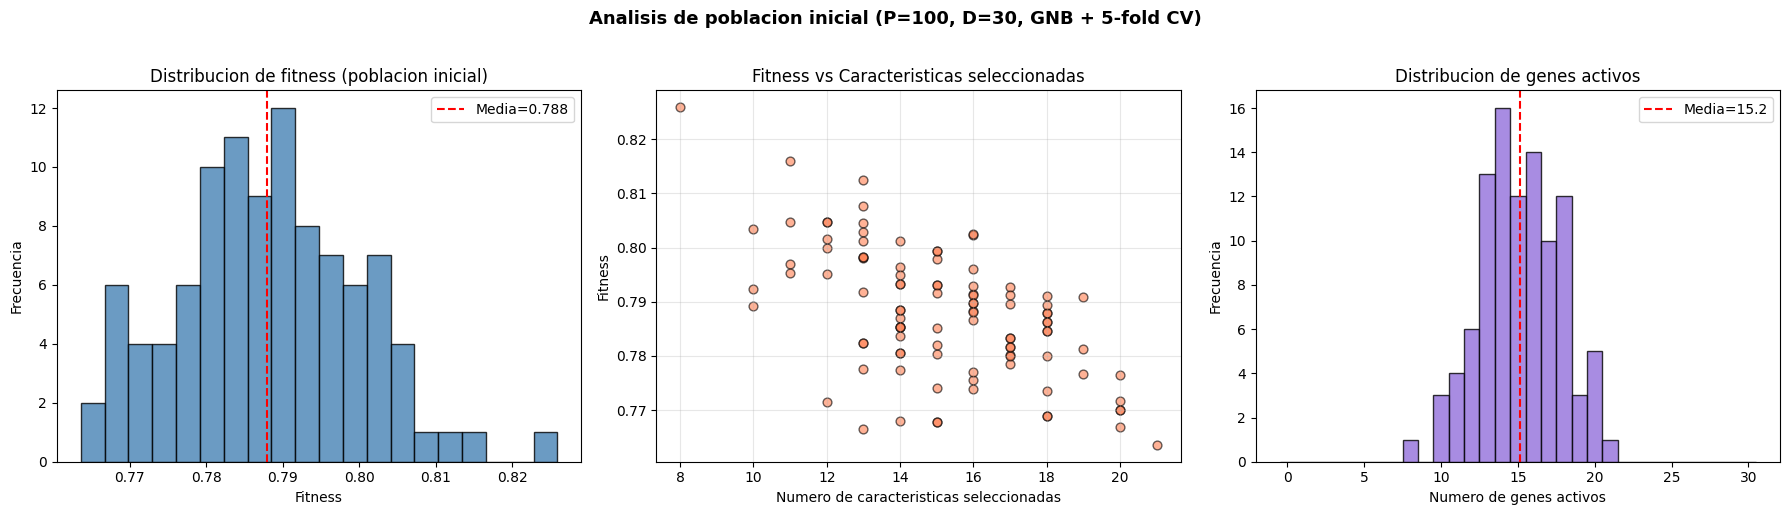

Grafico guardado en results/gnb_poblacion_inicial.png


In [24]:
import matplotlib.pyplot as plt

genes_por_individuo = [sum(ind) for ind in poblacion]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafico 1: Distribucion de fitness
axes[0].hist(fitness_seq, bins=20, color='steelblue', edgecolor='black', alpha=0.8)
axes[0].axvline(x=np.mean(fitness_seq), color='red', linestyle='--',
                label=f'Media={np.mean(fitness_seq):.3f}')
axes[0].set_xlabel('Fitness')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Distribucion de fitness (poblacion inicial)')
axes[0].legend()

# Grafico 2: Fitness vs Numero de caracteristicas
axes[1].scatter(genes_por_individuo, fitness_seq, alpha=0.6, color='coral', edgecolors='black', s=40)
axes[1].set_xlabel('Numero de caracteristicas seleccionadas')
axes[1].set_ylabel('Fitness')
axes[1].set_title('Fitness vs Caracteristicas seleccionadas')
axes[1].grid(True, alpha=0.3)

# Grafico 3: Distribucion de genes activos
axes[2].hist(genes_por_individuo, bins=range(0, D+2), color='mediumpurple',
             edgecolor='black', alpha=0.8, align='left')
axes[2].set_xlabel('Numero de genes activos')
axes[2].set_ylabel('Frecuencia')
axes[2].set_title('Distribucion de genes activos')
axes[2].axvline(x=np.mean(genes_por_individuo), color='red', linestyle='--',
                label=f'Media={np.mean(genes_por_individuo):.1f}')
axes[2].legend()

plt.suptitle(f'Analisis de poblacion inicial (P={P}, D={D}, GNB + {CV_FOLDS}-fold CV)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/gnb_poblacion_inicial.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/gnb_poblacion_inicial.png")

---
## 9. Ciclo Evolutivo Completo con Evaluacion Real

Ejecutamos varias generaciones del GA con la funcion fitness basada en GNB:
1. Evaluar fitness en paralelo (Spark + GNB + 5-fold CV)
2. Seleccion por torneo binario
3. Cruce de un punto y mutacion flip
4. Elitismo: preservar los 2 mejores individuos

In [25]:
import random
random.seed(42)

P_CROSS = 0.8
P_MUT = 0.2
P_MUT_BIT = 1 / D  # ~0.033 para D=30
ELITE_SIZE = 2

def torneo_binario(poblacion, fitness_scores):
    """Seleccion por torneo de tamano 2."""
    i, j = random.sample(range(len(poblacion)), 2)
    if fitness_scores[i] >= fitness_scores[j]:
        return list(poblacion[i])
    return list(poblacion[j])

def cruce_un_punto(padre1, padre2):
    """Cruce de un punto."""
    punto = random.randint(1, len(padre1) - 1)
    hijo1 = padre1[:punto] + padre2[punto:]
    hijo2 = padre2[:punto] + padre1[punto:]
    return hijo1, hijo2

def mutacion_flip(cromosoma, p_mut_bit):
    """Mutacion por inversion de bit."""
    return [1 - gen if random.random() < p_mut_bit else gen for gen in cromosoma]

def una_generacion(poblacion, fitness_scores):
    """Ejecuta una generacion completa del GA."""
    # Elitismo: preservar top-E
    indices_elite = sorted(range(len(fitness_scores)),
                           key=lambda i: fitness_scores[i], reverse=True)[:ELITE_SIZE]
    elite = [list(poblacion[i]) for i in indices_elite]

    # Generar descendencia
    descendencia = []
    while len(descendencia) < P - ELITE_SIZE:
        padre1 = torneo_binario(poblacion, fitness_scores)
        padre2 = torneo_binario(poblacion, fitness_scores)

        if random.random() < P_CROSS:
            hijo1, hijo2 = cruce_un_punto(padre1, padre2)
        else:
            hijo1, hijo2 = list(padre1), list(padre2)

        if random.random() < P_MUT:
            hijo1 = mutacion_flip(hijo1, P_MUT_BIT)
        if random.random() < P_MUT:
            hijo2 = mutacion_flip(hijo2, P_MUT_BIT)

        descendencia.extend([hijo1, hijo2])

    return elite + descendencia[:P - ELITE_SIZE]


print("Operadores geneticos definidos.")
print(f"  Cruce: un punto (p_cross={P_CROSS})")
print(f"  Mutacion: flip bit (p_mut={P_MUT}, p_mut_bit={P_MUT_BIT:.4f})")
print(f"  Elitismo: top {ELITE_SIZE}")

Operadores geneticos definidos.
  Cruce: un punto (p_cross=0.8)
  Mutacion: flip bit (p_mut=0.2, p_mut_bit=0.0333)
  Elitismo: top 2


In [26]:
NUM_GENERACIONES = 10

print(f"Simulacion de {NUM_GENERACIONES} generaciones del GA")
print(f"P={P}, D={D}, Clasificador=GNB, CV={CV_FOLDS}-fold")
print(f"alpha={ALPHA}, beta={BETA}")
print(f">>> Observa los jobs en http://localhost:4040 <<<\n")

pop = list(poblacion)  # copia
historico_mejor = []
historico_medio = []
historico_peor = []
historico_genes = []
tiempos_gen = []
mejor_global = None
mejor_fitness_global = -1

for gen in range(NUM_GENERACIONES):
    t0 = time.time()

    # Paso 1: Evaluacion paralela con Spark
    rdd_pop = sc.parallelize(pop, numSlices=NUM_CORES)
    scores = rdd_pop.map(evaluar_fitness).collect()

    mejor = max(scores)
    medio = np.mean(scores)
    peor = min(scores)
    genes_medio = np.mean([sum(ind) for ind in pop])

    historico_mejor.append(mejor)
    historico_medio.append(medio)
    historico_peor.append(peor)
    historico_genes.append(genes_medio)

    # Guardar mejor individuo global
    idx_mejor = scores.index(mejor)
    if mejor > mejor_fitness_global:
        mejor_fitness_global = mejor
        mejor_global = list(pop[idx_mejor])

    # Paso 2: Operadores geneticos
    pop = una_generacion(pop, scores)

    t_gen = time.time() - t0
    tiempos_gen.append(t_gen)

    print(f"  Gen {gen+1:>2d}/{NUM_GENERACIONES} | "
          f"Mejor={mejor:.6f} | Media={medio:.6f} | "
          f"Genes={genes_medio:.1f} | Tiempo={t_gen:.2f}s")

print(f"\nTiempo total: {sum(tiempos_gen):.2f}s")
print(f"Tiempo medio por generacion: {np.mean(tiempos_gen):.2f}s")
print(f"\nMejor fitness global: {mejor_fitness_global:.6f}")
print(f"Genes activos del mejor: {sum(mejor_global)}/{D}")

Simulacion de 10 generaciones del GA
P=100, D=30, Clasificador=GNB, CV=5-fold
alpha=0.9, beta=0.1
>>> Observa los jobs en http://localhost:4040 <<<

  Gen  1/10 | Mejor=0.825895 | Media=0.787899 | Genes=15.2 | Tiempo=0.11s
  Gen  2/10 | Mejor=0.825895 | Media=0.794682 | Genes=14.4 | Tiempo=0.08s
  Gen  3/10 | Mejor=0.825895 | Media=0.800640 | Genes=13.2 | Tiempo=0.09s
  Gen  4/10 | Mejor=0.827299 | Media=0.804769 | Genes=12.9 | Tiempo=0.08s
  Gen  5/10 | Mejor=0.841698 | Media=0.812223 | Genes=11.7 | Tiempo=0.08s
  Gen  6/10 | Mejor=0.846611 | Media=0.818947 | Genes=11.0 | Tiempo=0.07s
  Gen  7/10 | Mejor=0.853088 | Media=0.824602 | Genes=10.0 | Tiempo=0.07s
  Gen  8/10 | Mejor=0.853088 | Media=0.829510 | Genes=9.5 | Tiempo=0.08s
  Gen  9/10 | Mejor=0.853088 | Media=0.833183 | Genes=9.0 | Tiempo=0.08s
  Gen 10/10 | Mejor=0.853088 | Media=0.836326 | Genes=8.2 | Tiempo=0.07s

Tiempo total: 0.82s
Tiempo medio por generacion: 0.08s

Mejor fitness global: 0.853088
Genes activos del mejor: 6

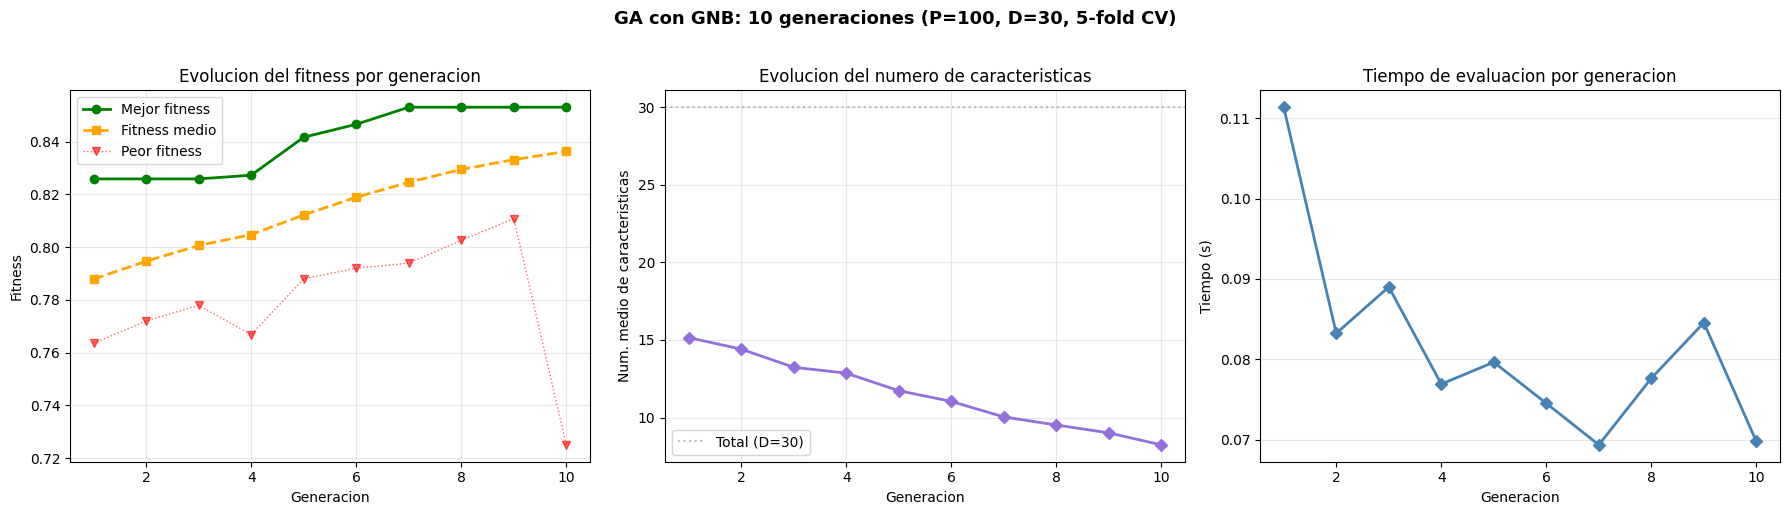

Grafico guardado en results/gnb_ga_evolucion.png


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

gens = range(1, NUM_GENERACIONES + 1)

# Grafico 1: Evolucion del fitness
axes[0].plot(gens, historico_mejor, 'o-', color='green', linewidth=2, label='Mejor fitness')
axes[0].plot(gens, historico_medio, 's--', color='orange', linewidth=2, label='Fitness medio')
axes[0].plot(gens, historico_peor, 'v:', color='red', linewidth=1, alpha=0.6, label='Peor fitness')
axes[0].set_xlabel('Generacion')
axes[0].set_ylabel('Fitness')
axes[0].set_title('Evolucion del fitness por generacion')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Grafico 2: Numero medio de caracteristicas
axes[1].plot(gens, historico_genes, 'D-', color='mediumpurple', linewidth=2)
axes[1].axhline(y=D, color='gray', linestyle=':', alpha=0.5, label=f'Total (D={D})')
axes[1].set_xlabel('Generacion')
axes[1].set_ylabel('Num. medio de caracteristicas')
axes[1].set_title('Evolucion del numero de caracteristicas')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Grafico 3: Tiempo por generacion
axes[2].plot(gens, tiempos_gen, 'D-',color='steelblue', linewidth=2)
axes[2].set_xlabel('Generacion')
axes[2].set_ylabel('Tiempo (s)')
axes[2].set_title('Tiempo de evaluacion por generacion')
axes[2].grid(True, alpha=0.3, axis='y')

plt.suptitle(f'GA con GNB: {NUM_GENERACIONES} generaciones (P={P}, D={D}, {CV_FOLDS}-fold CV)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../results/gnb_ga_evolucion.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafico guardado en results/gnb_ga_evolucion.png")

---
## 10. Mejor Individuo y Resumen

In [28]:
# Analisis del mejor individuo encontrado
indices_mejor = [i for i, gen in enumerate(mejor_global) if gen == 1]
nombres_mejor = feature_names[indices_mejor]

# Recalcular accuracy del mejor individuo (sin penalizacion)
gnb_final = GaussianNB()
scores_final = cross_val_score(gnb_final, X[:, indices_mejor], y, cv=CV_FOLDS, scoring='accuracy')

print("=" * 60)
print("MEJOR INDIVIDUO ENCONTRADO")
print("=" * 60)
print(f"Fitness:  {mejor_fitness_global:.6f}")
print(f"Accuracy (CV5): {scores_final.mean():.6f} (+/- {scores_final.std():.6f})")
print(f"Caracteristicas: {len(indices_mejor)}/{D} ({len(indices_mejor)/D*100:.0f}%)")
print(f"\nCaracteristicas seleccionadas:")
for i, nombre in enumerate(nombres_mejor):
    print(f"  {i+1:>2d}. {nombre}")

print(f"\n{'=' * 60}")
print(f"COMPARACION CON BASELINE (todas las caracteristicas)")
print(f"{'=' * 60}")
gnb_base = GaussianNB()
scores_base = cross_val_score(gnb_base, X, y, cv=CV_FOLDS, scoring='accuracy')
fitness_base = ALPHA * scores_base.mean() - BETA * 1.0

print(f"Baseline accuracy (CV5): {scores_base.mean():.6f} (+/- {scores_base.std():.6f})")
print(f"Baseline fitness:        {fitness_base:.6f}")
print(f"Mejor GA fitness:        {mejor_fitness_global:.6f}")
print(f"Mejora en fitness:       {mejor_fitness_global - fitness_base:+.6f}")
print(f"Reduccion caracteristicas: {D} -> {len(indices_mejor)} ({(1 - len(indices_mejor)/D)*100:.0f}% menos)")
print("=" * 60)

MEJOR INDIVIDUO ENCONTRADO
Fitness:  0.853088
Accuracy (CV5): 0.970098 (+/- 0.011991)
Caracteristicas: 6/30 (20%)

Caracteristicas seleccionadas:
   1. mean texture
   2. worst radius
   3. worst texture
   4. worst perimeter
   5. worst smoothness
   6. worst concave points

COMPARACION CON BASELINE (todas las caracteristicas)
Baseline accuracy (CV5): 0.938519 (+/- 0.014586)
Baseline fitness:        0.744667
Mejor GA fitness:        0.853088
Mejora en fitness:       +0.108421
Reduccion caracteristicas: 30 -> 6 (80% menos)


In [29]:
X_bc.destroy()
y_bc.destroy()
parar_spark(spark)

✓ Spark session detenida
